In [1]:
import numpy as np
import glob
import matplotlib.pyplot as plt
import netCDF4 as nc4
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
import matplotlib.ticker as mticker
#import jdcal
import pickle as pkl
import math
import sim_name_remap as snr
import plotter_config as pc
#from plot_ACCLIP_profs import plot_model_overlay, get_ACCLIP_merge_data, get_model_prof_data

In [2]:
###################
# The purpose of this script is to calculate average chemical profiles for grid cells with active convection
# and compare the impoact of ZMKE convection
###################

In [3]:

def alt2prs(alts, H, P0):
    result = P0*np.exp(-1.0*alts/H)
    return result
      
def prs2alt(prs, H, P0):
    result = -1.0*H*np.log(prs/P0)
    return result
    

In [4]:

region = [95,125,30,45]  # The box where cloud tops are compared   - East Asia box
#region = [125,140,25,38]  # ACCLIP box
#region = [0,360,-20,20]  # Tropics
var_name = 'ZMMU'
#deepconv_thresh = 200.  # Pressure level threshold (hPa) above which we consider convection to be "deep"
#convprec_thresh = 5.    # Convective precipitation threshold (mm/day) above which we consider convection "active"

date0 = '2022-08-01'
date1 = '2022-08-31'


In [5]:

# Define a function that will calculate an average convective profile

def calc_mean_model_convprof(sim, var_name, region, deepconv_thresh, convprec_thresh, date0, date1):

    sim_path = snr.remap[sim]
    
    FILES = sorted(glob.glob(sim_path))
    FILES0 = [item for item in FILES if date0 in item][0]
    find0 = list(FILES).index(FILES0)
    FILES1 = [item for item in FILES if date1 in item][0]
    find1 = list(FILES).index(FILES1)
    FILES = FILES[find0:find1+1]    

    var_str = pc.var_info[var_name]['vars']
    
    print(sim_path)
    
    cloudtops = []
    conv_precip = []
    
    file0 = nc4.Dataset(FILES[0])
    lev = file0.variables['lev'][:]

    var_convprofiles = np.zeros((1,len(lev)))-999
    var_nonconvprofiles = np.zeros((1,len(lev)))-999
    
    for f in range(len(FILES)):
        if f % 1 == 0: print(FILES[f])
        
        file = nc4.Dataset(FILES[f])
        lon = file.variables['lon'][:]
        lat = file.variables['lat'][:]    
        model_cldtops = file.variables['PCONVT'][:]/100.          # Convert to hPa
        model_convprec = file.variables['PRECC'][:]*1000.*86400.  # Convert to mm/day

        if isinstance(var_str, str): model_var = file.variables[var_str][:]
        if isinstance(var_str, list):
            model_var = file.variables[var_str[0]][:]
            for sub_v in range(len(var_str)-1):
                curr_sub_var = file.variables[var_str[sub_v+1]][:]
                model_var = model_var + curr_sub_var
        
        model_var = model_var*pc.var_info[var_name]['mod']
        
        for ln in range(len(lon)):
            for lt in range(len(lat)):
    
                curr_lon = lon[ln]
                curr_lat = lat[lt]
    
                if curr_lon >= region[0] and curr_lon <= region[1] and curr_lat >= region[2] and curr_lat <= region[3]:                
    
                    curr_cldtop = model_cldtops[:,lt,ln]
                    curr_convprec = model_convprec[:,lt,ln]
    
                    for t in range(len(curr_cldtop)):
    
                        curr_curr_cldtop = curr_cldtop[t]
                        curr_curr_convprec = curr_convprec[t]
                        
                        cloudtops.append(curr_curr_cldtop)
                        conv_precip.append(curr_curr_convprec)

                        # Put the convective-only profiles into a separate array
                        if curr_curr_cldtop <= deepconv_thresh and curr_curr_convprec >= convprec_thresh:
                            var_convprofiles = np.append(var_convprofiles, model_var[t,:,lt,ln][None,:], axis=0)                            
                        else:            
                            if lt % 5 == 0 and ln % 5 == 0:   # Done to save on calculation time
                                var_nonconvprofiles = np.append(var_nonconvprofiles, model_var[t,:,lt,ln][None,:], axis=0)  # This may add a lot of computational expense
                                

    var_nonconvprofiles = var_nonconvprofiles[1:,:]
    var_convprofiles = var_convprofiles[1:,:]
    
    #print(np.shape(var_profiles))
    
    return var_convprofiles, var_nonconvprofiles, cloudtops, conv_precip, lev
    

In [6]:

# Read obs

#ERICA_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_ERICA_Merge/'
#ERICA_FLT_DATES = ['20220804','20220806','20220807','20220812','20220815','20220816','20220819','20220822','20220823','20220825','20220826']

#ACCLIP_GV_ERICA_prs = get_ACCLIP_merge_data(ERICA_OBSROOT, ERICA_FLT_DATES, 'PSXC') 
#ACCLIP_ERICA_SO4 = get_ACCLIP_merge_data(ERICA_OBSROOT, ERICA_FLT_DATES, 'sulphate_AMS')   # Raw units of ug/m3  


In [7]:

# Mean the profiles together to a single profile and plot
conv_profiles_E5_ZMKE, nonconv_profiles_E5_ZMKE, cloudtops, conv_precip, lev = calc_mean_model_convprof('2022_ERA5_ZMKE', var_name, region, 200., 20., date0, date1)   # 'Aug19_ERA5_0.25nudge'
conv_profiles_E5_ZM, nonconv_profiles_E5_ZM, cloudtops, conv_precip, lev = calc_mean_model_convprof('2022_ERA5_ZM', var_name, region, 200., 20., date0, date1)     # 'Aug19_ERA5_0.25nudge_noZMKE'

#mean_prof_ZMKE, lev   = calc_mean_model_convprof('MAM4_MEIC_SO2_ZMKE')


/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE/atm/hist/F*h1*
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE.cam.h1.2022-08-01-10800.nc
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE.cam.h1.2022-08-02-10800.nc
/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_ZMKE/atm/hist/FCnudged_f09.carmats16_cesm2.2.carma_trop_strat.2010_2021_cams5.3_so2_meic_withbb_RichConv.002.2022_E5_Z

In [8]:

conv_profiles_E5_ZMKE_mean = np.mean(conv_profiles_E5_ZMKE, axis=0)
nonconv_profiles_E5_ZMKE_mean = np.mean(nonconv_profiles_E5_ZMKE, axis=0)

conv_profiles_E5_ZM_mean = np.mean(conv_profiles_E5_ZM, axis=0)
nonconv_profiles_E5_ZM_mean = np.mean(nonconv_profiles_E5_ZM, axis=0)


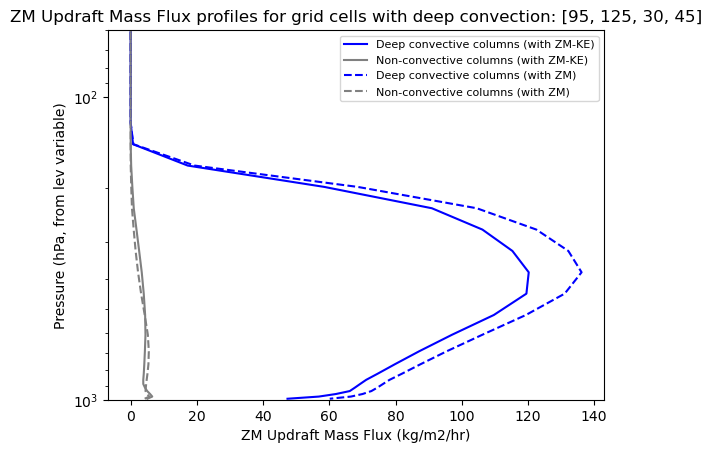

In [9]:

plt.plot(conv_profiles_E5_ZMKE_mean, lev, color='blue', label='Deep convective columns (with ZM-KE)')
plt.plot(nonconv_profiles_E5_ZMKE_mean, lev, color='gray', label='Non-convective columns (with ZM-KE)')

plt.plot(conv_profiles_E5_ZM_mean, lev, color='blue', linestyle='--', label='Deep convective columns (with ZM)')
plt.plot(nonconv_profiles_E5_ZM_mean, lev, color='gray', linestyle='--', label='Non-convective columns (with ZM)')

#plt.scatter(ACCLIP_ERICA_SO4, ACCLIP_GV_ERICA_prs, s=0.5, color='k')

plt.yscale('log')
#plt.xscale('log')
plt.ylim(1000,60)
#plt.xlim(0,1.2)  # temporary for sulfate only

plt.xlabel(pc.var_info[var_name]['lab'] + ' (' + pc.var_info[var_name]['unit'] + ')')
plt.ylabel('Pressure (hPa, from lev variable)')
plt.title(pc.var_info[var_name]['lab'] + ' profiles for grid cells with deep convection: ' + str(region))

plt.legend(fontsize=8)


In [10]:

# Another plot setup
#var_name = 'ZMMD' 

#mean_prof_noZMKE, allprofiles, cloudtops, conv_precip, lev = calc_mean_model_convprof('MAM4_MEIC_SO21', var_name, region, 500., 5.)
#mean_prof_ZMKE, allprofiles, cloudtops, conv_precip, lev = calc_mean_model_convprof('MAM4_MEIC_SO2_ZMKE1', var_name, region, 500., 5.)


In [11]:

#plt.plot(mean_prof_noZMKE, lev, color='cyan', label='No ZMKE')
#plt.plot(mean_prof_ZMKE, lev, color='blue', label='ZMKE')
#
#plt.yscale('log')
#plt.ylim(1000,80)
#
#plt.xlabel(vc.var_info[var_name]['lab'] + ' (' + vc.var_info[var_name]['unit'] + ')')
#plt.ylabel('Pressure (hPa, from lev variable)')
#plt.title(vc.var_info[var_name]['lab'] + ' profiles for grid cells with deep convection: ' + str(region))
#
#plt.legend()


In [12]:

def plot_var_vs_convprec(sim, var_name, region):

    mean_prof_ZMKE, allprofiles, cloudtops, conv_precip, lev = calc_mean_model_convprof(sim, var_name, region, 500., 5.)
    
    bins = np.logspace(-1,2,endpoint=False,num=20)  # precip bins in mm/day
    bins_plot = []  # This will be the midpoints
    
    var_vs_convprec = np.zeros((1,len(lev)))-999
    
    for b in range(len(bins)-1):
    
        curr_binmin = bins[b]
        curr_binmax = bins[b+1]
        bins_plot.append(np.mean([curr_binmin, curr_binmax]))
        
        curr_inds = np.where((conv_precip >= curr_binmin) & (conv_precip <= curr_binmax))[0]
        curr_meanprof = np.mean(allprofiles[curr_inds,:], axis=0)[None,:]
        var_vs_convprec = np.append(var_vs_convprec, curr_meanprof, axis=0)
    
    var_vs_convprec = var_vs_convprec[1:,:]
    
    cmap = plt.get_cmap('YlOrRd')
    levels = np.arange(20,61,5)
    norm = BoundaryNorm(levels, cmap.N)
    
    c = plt.contourf(bins_plot, lev, np.transpose(var_vs_convprec), cmap=cmap, norm=norm, levels=levels, extend='both')
    plt.colorbar(c, label = vc.var_info[var_name]['lab'] + ' (' + vc.var_info[var_name]['unit'] + ')')
    
    plt.xlim(0.1,70)
    plt.ylim(1000,80)
    plt.xscale('log')
    plt.yscale('log')

    plt.title(sim)
    plt.ylabel('Pressure (hPa)')
    plt.xlabel('Convective Precipitation (mm/day)')



In [13]:

# Read information for a 2D contour plot of array vs convective precip

#plot_var_vs_convprec('MAM4_MEIC_SO2_ZMKE1', 'E90', region)


In [14]:

#plot_var_vs_convprec('MAM4_MEIC_SO21', 'E90', region)


In [15]:
#plt.scatter(conv_precip, cloudtops)